<a href="https://colab.research.google.com/github/kmiloperez-data/Proyecto-7-Explorando-drivers-de-comportamiento-en-NovaRetail-/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`


La mayoría de estas variables presentan tipos de datos adecuados.  
La columna de edad se guardo como `float64`, "nuemro decimal", al imprimir las 5 primeras filas del dataset, se confirma que este formato se debe a que el archivo `CSV` la edad ya venia escrita con decimales, y pandas simplemente respeto el formato que se encontro en el archivo original.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.
**Nota**
Se identifica la columna `id_cliente`como identificador único de tipo texto/string, aparece descrito como "Identificador único", no como variable categórica.

In [ ]:
# Corregir el tipo de dato
df_copy= df.copy()
df_copy['edad'] = df_copy['edad'].astype(int)

In [ ]:
# verificar cambios
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
df_copy.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` — el rango parece normal (oscila entre los 18 años y 75 años, con una media de 38.26 años).
- `nivel_ingreso` — el rango parece normal (va desde los 8.000 hasta los 74.790,84 con una media cercana a los 30019).
- `visitas_mes`— muestra un comportamiento centrado, con un promedio de 10 visitas mensuales y un rango que va de 1 a 25.
- `compras_mes` — destaca que el primer perncentil 25% y el minimo se encuentran en 0, indicando que una parte de los clientes no realiza compras mensuales, con una media general baja de 1.2 compras.
- `gasto_publicidad_dirigida` — presenta un valor minimo de 0 y se extiende hasta un maximo de 75.51, con una media de 20.14.
- `satisfaccion` — se mantiene de forma coherente dentro de la escala establecida de 1 a 5, con una media de 3.6 y una baja dispersión (desviación estándar de 0.68)
- `ingreso_anual` — un detalle relevante es que el mínimo y el percentil 25 son 0, lo que sugiere la presencia de clientes que no generan ingresos para la empresa, alcanzando un valor máximo de 244.69.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles

columnas_a_revisar = ["miembro_premium", "abandono"]

for col in columnas_a_revisar:
    print(f"--- Distribución de la columna: {col} ---")
    print(df_copy[col].value_counts())
    print("\n" + "="*40 + "\n")

--- Distribución de la columna: miembro_premium ---
0    12911
1     2089
Name: miembro_premium, dtype: int64


--- Distribución de la columna: abandono ---
0    12739
1     2261
Name: abandono, dtype: int64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — Variable binaria sin valores inesperados. La gran mayoría de los clientes de NovaRetail+ durante 2024 son estándar (86%, 12.911 clientes), y los premium (codificados como 1) son el 14% restante (2.089 clientes). Hay un desbalance de clases a considerar.
- `abandono` — Variable binaria sin valores inesperados. La tasa de abandono general es del 15% (2.261 clientes), con 85% de clientes que permanecen. También hay desbalance de clases.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
columnas_a_revisar = ["tipo_dispositivo", "region"]

for col in columnas_a_revisar:
    print(f"--- Valores únicos: {col} ---")
    print(df_copy[col].nunique())
    print("\n" + "="*40 + "\n")

--- Valores únicos: tipo_dispositivo ---
3


--- Valores únicos: region ---
4




In [ ]:
# Explorar variables categóricas y cómo se distribuyen
columnas_a_revisar = ["tipo_dispositivo", "region"]

for col in columnas_a_revisar:
    print(f"---  Distribución de la columna: {col} ---")
    print(df_copy[col].value_counts())
    print("\n" + "="*40 + "\n")

---  Distribución de la columna: tipo_dispositivo ---
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64


---  Distribución de la columna: region ---
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — la categoría  móvil es la dominante (9818), seguida de escritorio (3720) y tablet (1462).
- `region` - las cuatro regiones están bastante balanceadas, con norte liderando ligeramente (4395) y este con menos registros (3069).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

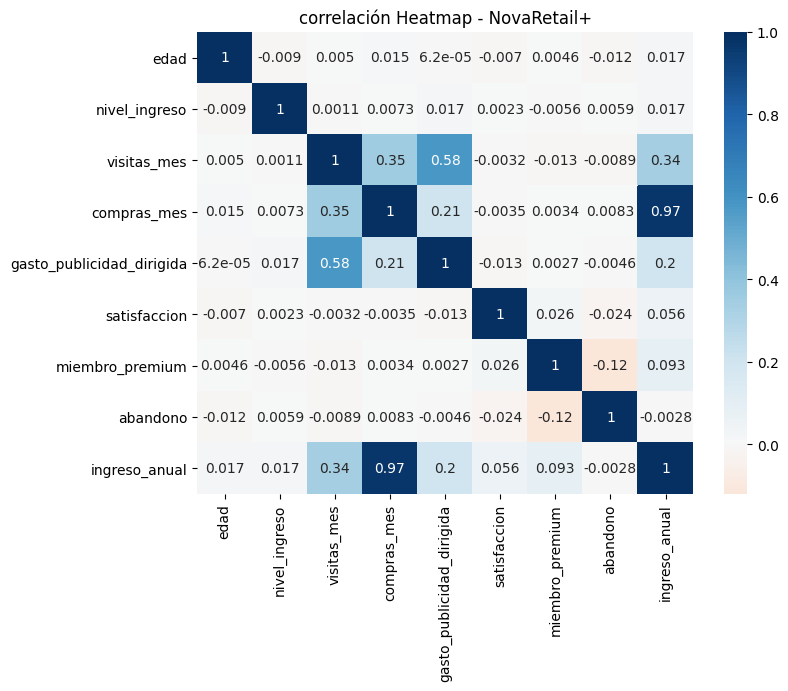

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr= df_copy.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu", center=0)
plt.title('correlación Heatmap - NovaRetail+')
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- `Se observa`:
- Independencia de la edad y satisfacción: La variable edad y la variable satisfaccion muestran coeficientes de correlación cercanos a 0 frente a casi todas las demás variables. Esto indica que no existe una relación lineal directa entre la       edad de los clientes o su nivel de satisfacción y el resto de los factores analizados.
- Correlación moderada en visitas y publicidad: Existe una correlación positiva moderada (0.58) entre visitas_mes y gasto_publicidad_dirigida, lo que sugiere que las campañas de publicidad dirigida tienen un impacto positivo directo en la         frecuencia con la que los usuarios visitan la plataforma.
- Correlación baja con el abandono: La variable abandono presenta valores muy cercanos a 0 (y ligeramente negativos) con todas las demás variables numéricas, lo que indica que el comportamiento de deserción no está fuertemente correlacionado de   manera lineal con una sola métrica cuantitativa aislada.


Observaciones respecto a `ingreso_anual`  
- `Presenta`:
- Fuerte correlación con las compras mensuales ($0.97$): El dato más sobresaliente del mapa de calor es la altísima correlación positiva (0.97) entre ingreso_anual y compras_mes. Esto indica que los clientes con mayor ingreso anual son, por un    margen muy claro, los que realizan un mayor volumen de compras mensuales en NovaRetail+.
- Correlación moderada con las visitas mensuales ($0.34$): Se observa una relación positiva moderada (0.34) con visitas_mes, lo que demuestra que un mayor ingreso anual también se alinea con una frecuencia de visitas superior a la                 plataforma.
- Correlación baja con el gasto publicitario ($0.20$): Aunque hay una ligera tendencia positiva con gasto_publicidad_dirigida, la correlación es baja (0.20), lo que indica que el nivel de ingreso anual no depende fuertemente de este tipo de       pauta publicitaria.
- Independencia del abandono ($-0.0028$): Prácticamente no existe correlación lineal entre el ingreso_anual y el abandono, lo que señala que los usuarios que abandonan la plataforma se distribuyen de manera uniforme sin importar su nivel de       ingresos anuales.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
  - Se determina no incluir una matriz de gráficos de dispersión (scatterplot) general para todo el conjunto de datos, dado que el objetivo central del análisis se encuentra acotado y enfocado específicamente en la métrica de ingreso_anual. El      análisis previo de correlación (heatmap) demostró que la gran mayoría de las variables poseen una relación lineal nula o irrelevante con los ingresos, concentrando los inductores clave de valor únicamente en tres variables (compras_mes,         visitas_mes y gasto_publicidad_dirigida). En consecuencia, generar un gráfico de dispersión masivo con todas las dimensiones del dataset produciría ruido visual redundante y sin valor analítico; por lo que metodológicamente es más eficiente     y limpio orientar los esfuerzos visuales de forma exclusiva hacia las variables que impactan directamente el foco de estudio.

### Scatterplot para pares clave

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes


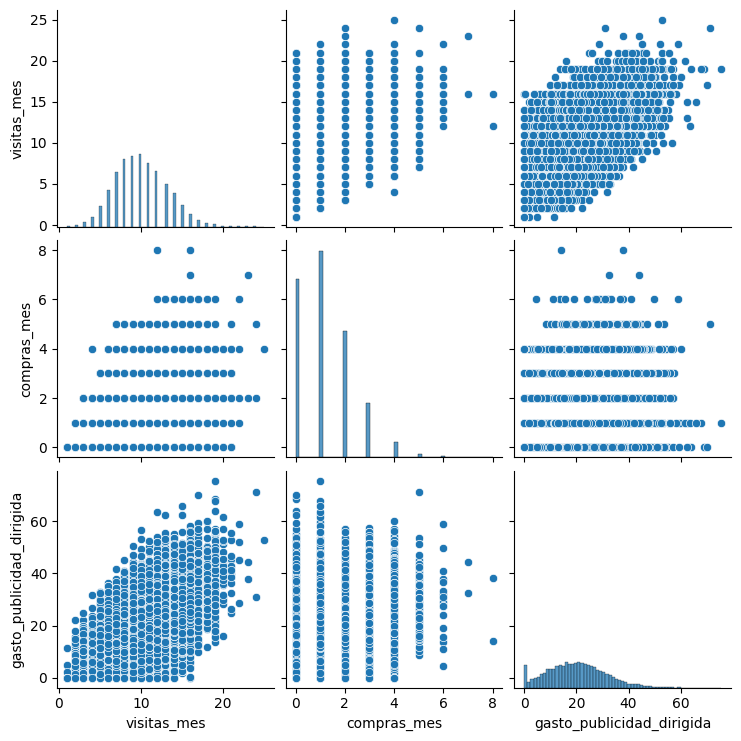

In [ ]:
sns.pairplot(df_copy[['visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida']])
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**var1 vs var2**
- Dirección  Positiva; los usuarios que acceden con mayor frecuencia a la plataforma tienden a registrar un mayor volumen de transacciones mensuales.
- Dispersión: Media; los puntos se encuentran distribuidos en un rango más amplio, reflejando que la relación no es totalmente estricta ni uniforme para todos los clientes.
- Outliers: Se identifican algunos valores atípicos superiores (clientes con un volumen de compras elevado a pesar de tener un nivel de visitas moderado).
- Posible colinealidad: Baja a moderada ($r = 0.35$), indicando que un mayor tráfico por sí solo no garantiza una conversión lineal directa en compras.
  
**var1 vs var3**
- Dirección Positiva; se observa claramente que a mayor inversión en publicidad dirigida, incrementa la frecuencia de visitas mensuales a la plataforma.
- Dispersión: Media-baja; los datos muestran una tendencia lineal ascendente bien definida y concentrada en la franja central.
- Outliers: Presencia de algunos puntos aislados en el extremo superior derecho que se separan de la densidad principal de la distribución.
- Posible colinealidad: Moderada ($r = 0.58$), lo que confirma que las campañas publicitarias son un vector importante para estimular el tráfico recurrente de los usuarios.
  

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
pearson_corr = df_copy['visitas_mes'].corr(df_copy['compras_mes'],method='pearson')
spearman_corr = df_copy['visitas_mes'].corr(df_copy['compras_mes'],method='spearman')
print('Pearson=', pearson_corr)
print('Spearman=', spearman_corr)

Pearson= 0.3538438947198978
Spearman= 0.33294292722789276


In [ ]:
# Calcular correlación entre variables relevantes
pearson_corr = df_copy['visitas_mes'].corr(df_copy['gasto_publicidad_dirigida'],method='pearson')
spearman_corr = df_copy['visitas_mes'].corr(df_copy['gasto_publicidad_dirigida'],method='spearman')
print('Pearson=', pearson_corr)
print('Spearman=', spearman_corr)

Pearson= 0.5789472719412827
Spearman= 0.5592673242622609


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**var1 vs var2**
- Correlación y dirección: Positiva, con valores de Pearson ($0.35$) y Spearman ($0.33$), lo que indica que los usuarios con mayor frecuencia de visitas mensuales tienden a registrar un incremento en su volumen de compras.
- Magnitud y colinealidad: Baja a moderada; esto demuestra que no existe un problema de colinealidad fuerte, evidenciando que un mayor tráfico por sí solo no se traduce de manera lineal y directa en más compras.

**var2 vs var3**
- Correlación y dirección: Positiva, con coeficientes más marcados de Pearson ($0.58$) y Spearman ($0.56$), reflejando que a mayor inversión en pauta publicitaria dirigida, incrementan las visitas mensuales a la plataforma.
- Magnitud y colinealidad: Moderada; señala una relación estrecha pero manejable entre ambas variables, confirmando que la pauta publicitaria es un motor importante para dinamizar el tráfico de los usuarios.
  

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
columnas_a_revisar = ["miembro_premium", "abandono"]

for col in columnas_a_revisar:
    pb,_ = pointbiserialr(df_copy['visitas_mes'], df_copy[col])
    print(f"--- Punto-biserial : {col} {pb:.3f}")
    print("\n" + "="*40 + "\n")

--- Punto-biserial : miembro_premium -0.013


--- Punto-biserial : abandono -0.009




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**var1 vs var2**
- Relación y dirección: Negativa muy débil, con un coeficiente de $-0.013$, lo que indica que prácticamente no existe una relación lineal entre la frecuencia de visitas mensuales de los usuarios y su condición de miembros premium.
- Magnitud: Baja/Nula; demuestra que la cantidad de accesos a la plataforma se distribuye de manera muy similar tanto en clientes estándar como en usuarios premium, sin ser un factor diferenciador directo entre ambos segmentos.

**var2 vs var3**
- Relación y dirección: Negativa muy débil, con un coeficiente de $-0.009$, señalando que tampoco hay una correlación lineal relevante entre la frecuencia de visitas y la probabilidad de que un usuario abandone la plataforma.
- Magnitud: Baja/Nula; sugiere que el comportamiento de deserción ocurre de forma transversal en los usuarios independientemente de cuántas veces visiten NovaRetail+ al mes.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
def cramer_v(df_copy, col1, col2)

In [ ]:
# Aplicar V de Cramér en variables relevantes
from scipy.stats import chi2_contingency
col1 = "region"
col2 = 'tipo_dispositivo'
col3 = 'miembro_premium'
def cramers_v(df_copy, col1, col2):
    tabla = pd.crosstab(df_copy[col1], df_copy[col2])
    chi2, p, dof, expected = chi2_contingency(tabla)
    n = tabla.sum().sum()
    coef_v = np.sqrt(chi2/(n*(min(tabla.shape)-1)))
    print(f"V de Cramér ({col1} vs {col2}):", coef_v)
cramers_v(df_copy, col1, col2)
cramers_v(df_copy, col1, col3)
cramers_v(df_copy, col2, col3)

V de Cramér (region vs tipo_dispositivo): 0.012378338407739397
V de Cramér (region vs miembro_premium): 0.012574183027958334
V de Cramér (tipo_dispositivo vs miembro_premium): 0.01972543445542166


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér: Se observa que todos los coeficientes calculados son extremadamente bajos (por debajo de $0.02$), lo que indica que no existe una asociación estadísticamente relevante entre las variables categóricas evaluadas (region, tipo_dispositivo y miembro_premium). Esto demuestra que dichas variables operan de forma independiente dentro del conjunto de datos de NovaRetail+.
]


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 —

**Evidencia visual:** Mapa de calor de correlación (Heatmap) y diagrama de dispersión (Pairplot).   
**Evidencia numérica:** Coeficiente de correlación de Pearson de $0.97$ entre ingreso_anual y compras_mes.

**Interpretación** Los clientes que generan un mayor valor económico para NovaRetail+ son, de manera casi perfecta y lineal, aquellos que registran un mayor volumen de compras mensuales en la plataforma.


**No podemos afirmar** Que el incremento del ingreso anual dependa exclusivamente de la cantidad de transacciones sin considerar el ticket promedio, ni que exista una causalidad unidireccional absoluta.


**Implicación de negocio** Las estrategias comerciales y de retención deben concentrarse en incentivar la frecuencia de las compras mensuales, ya que representan el principal vector de monetización y salud financiera de la compañía.


### Hallazgo 2 —

**Evidencia visual:** Mapa de calor de correlación y matrices de dispersión bivariadas.
**Evidencia numérica:** Coeficiente de correlación de Pearson de $0.58$ (y Spearman de $0.56$) entre gasto_publicidad_dirigida y visitas_mes.

**Interpretación** Existe una relación positiva moderada que indica que a mayor inversión en pauta publicitaria dirigida, mayor es la frecuencia de visitas mensuales de los usuarios a la plataforma.


**No podemos afirmar** Que la inversión publicitaria garantice por sí sola una conversión directa en compras ($0.21$ de correlación con compras), ni que todo el tráfico de la plataforma provenga exclusivamente de pauta pagada.


**Implicación de negocio** La publicidad dirigida es un mecanismo eficaz para dinamizar el tráfico y la recurrencia de los usuarios, pero requiere optimizar los embudos de conversión para transformar eficazmente esas visitas en transacciones monetarias.


## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad: Los coeficientes analizados demuestran asociaciones estadísticas y tendencias lineales, pero no prueban una relación de causa y efecto directa entre las variables.
- Alcance temporal estático: El análisis se basa en un conjunto de datos transversal correspondiente al periodo 2024, sin incorporar series temporales longitudinales que permitan evaluar la evolución y estacionalidad del comportamiento de los     usuarios a lo largo del tiempo.

### **Próximos pasos**

Probar segmentación adicional
- [opcion 1] Analizar el comportamiento transaccional segmentando de forma cruzada por tipo de dispositivo (tipo_dispositivo) y región geográfica (region) para identificar posibles nichos de mercado desatendidos.
- [opcion 2] Profundizar en el perfil socioeconómico y de comportamiento del segmento de clientes estándar ($86\%$ de la base) para diseñar campañas focalizadas de conversión hacia membresías premium.

[Paso 2]
- [opcion 1] Desarrollar modelos de Machine Learning supervisado (como Regresión Logística o árboles de decisión) para estimar la probabilidad de deserción (churn) de los usuarios y accionar planes de retención preventivos.

[Paso 3]
- [opcion 1] Ejecutar un análisis detallado del Retorno de Inversión (ROI) de las campañas de gasto_publicidad_dirigida para medir su impacto real sobre el valor de vida del cliente (LTV).